# **PCD Assignment 3**

Ahmad Farhan Hidayat | 25/559740/PA/23558

# **Load Gambar**

Mounted at /content/drive


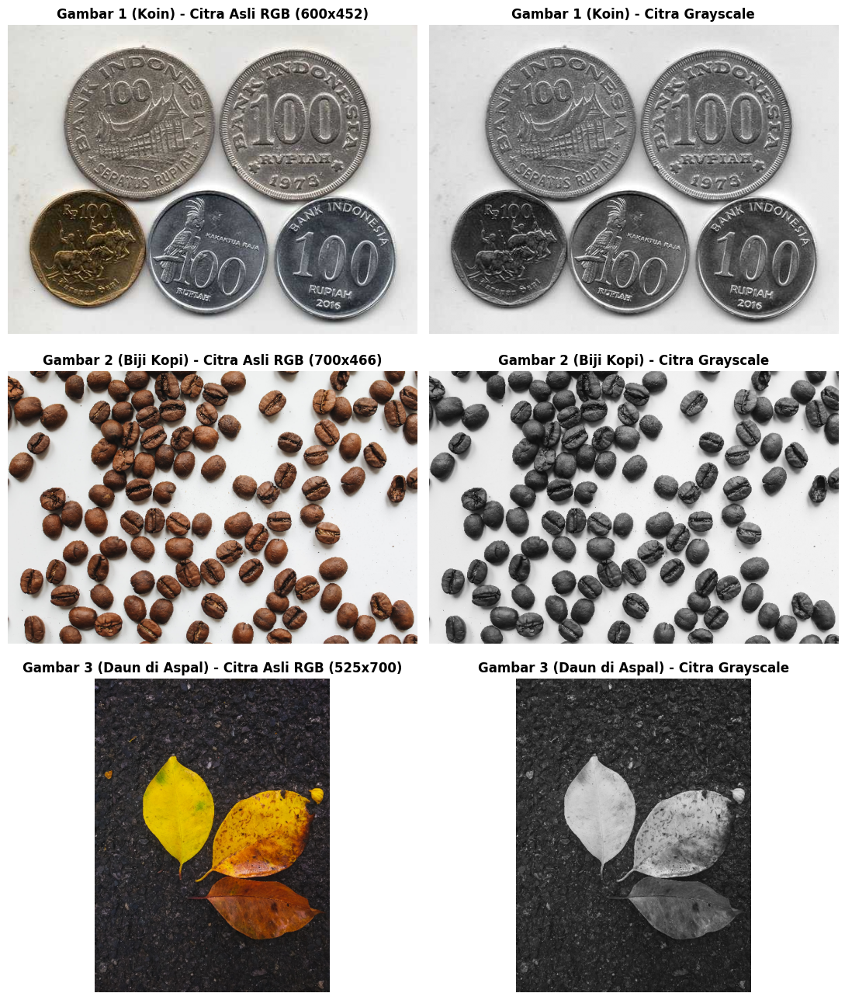

In [1]:
import os
from google.colab import drive
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/PCD Assignment 3/'

def load_and_preprocess_manual(filepath, max_dim=700):
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"File tidak ditemukan: {filepath}")

    img_pil = Image.open(filepath).convert('RGB')
    rgb_arr = np.array(img_pil, dtype=np.float32)

    h_orig, w_orig, _ = rgb_arr.shape
    scale = min(max_dim / h_orig, max_dim / w_orig, 1.0)

    if scale < 1.0:
        h_new, w_new = int(h_orig * scale), int(w_orig * scale)
        idx_y = (np.arange(h_new) / scale).astype(int)
        idx_x = (np.arange(w_new) / scale).astype(int)
        rgb_arr = rgb_arr[idx_y[:, None], idx_x]

    # Rumus manual Grayscale: Y = 0.299*R + 0.587*G + 0.114*B
    gray_img = (0.299 * rgb_arr[:, :, 0] +
                0.587 * rgb_arr[:, :, 1] +
                0.114 * rgb_arr[:, :, 2]).astype(np.uint8)

    return rgb_arr.astype(np.uint8), gray_img

# Konfigurasi dataset gambar
dataset_config = [
    {'file': 'gambar_1.jpeg', 'name': 'Gambar 1 (Koin)', 'invert': True,  'rg_t': 20, 'se_shape': 'disk'},
    {'file': 'gambar_2.jpg', 'name': 'Gambar 2 (Biji Kopi)', 'invert': True,  'rg_t': 22, 'se_shape': 'disk'},
    {'file': 'gambar_3.jpg', 'name': 'Gambar 3 (Daun di Aspal)', 'invert': False, 'rg_t': 25, 'se_shape': 'square'}
]

images_rgb = {}
images_gray = {}

# Load & langsung tampilkan perbandingan RGB vs Grayscale
fig, axes = plt.subplots(3, 2, figsize=(11, 13))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    rgb, gray = load_and_preprocess_manual(os.path.join(BASE_DIR, fname), max_dim=700)
    images_rgb[fname] = rgb
    images_gray[fname] = gray

    axes[idx, 0].imshow(rgb)
    axes[idx, 0].set_title(f"{cfg['name']} - Citra Asli RGB ({gray.shape[1]}x{gray.shape[0]})", fontweight='bold')
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(gray, cmap='gray')
    axes[idx, 1].set_title(f"{cfg['name']} - Citra Grayscale", fontweight='bold')
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

# **Segmentasi**

## **Otsu Thresholding**

### Definisi Fungsi

In [2]:
def compute_histogram_manual(gray_img):
    """Menghitung frekuensi intensitas piksel (0-255) secara manual."""
    hist = [0] * 256
    flat = gray_img.ravel()
    for val in flat:
        hist[int(val)] += 1
    return hist

def otsu_threshold_manual(gray_img, invert_foreground=False):
    """
    Implementasi Otsu's Method dari nol dengan mencari nilai T
    yang meminimalkan Within-Class Variance.
    """
    hist = compute_histogram_manual(gray_img)
    total_pixels = gray_img.size

    best_T = 0
    min_within_var = float('inf')

    for T in range(256):
        count_b = sum(hist[:T])
        count_f = sum(hist[T:])

        if count_b == 0 or count_f == 0:
            continue

        W_b = count_b / total_pixels
        W_f = count_f / total_pixels

        mu_b = sum(i * hist[i] for i in range(0, T)) / count_b
        mu_f = sum(i * hist[i] for i in range(T, 256)) / count_f

        var_b = sum(((i - mu_b) ** 2) * hist[i] for i in range(0, T)) / count_b
        var_f = sum(((i - mu_f) ** 2) * hist[i] for i in range(T, 256)) / count_f

        within_var = (W_b * var_b) + (W_f * var_f)

        if within_var < min_within_var:
            min_within_var = within_var
            best_T = T

    # Hitung ulang varians khusus pada best_T untuk mendapatkan Standar Deviasi Objek
    count_b = sum(hist[:best_T])
    count_f = sum(hist[best_T:])
    mu_b = sum(i * hist[i] for i in range(0, best_T)) / count_b
    mu_f = sum(i * hist[i] for i in range(best_T, 256)) / count_f

    var_b = sum(((i - mu_b) ** 2) * hist[i] for i in range(0, best_T)) / count_b
    var_f = sum(((i - mu_f) ** 2) * hist[i] for i in range(best_T, 256)) / count_f

    # Binarisasi matriks: 1 = Foreground (Objek), 0 = Background
    if invert_foreground:
        binary_mask = (gray_img < best_T).astype(np.uint8)
        std_obj = float(np.sqrt(var_b))
    else:
        binary_mask = (gray_img >= best_T).astype(np.uint8)
        std_obj = float(np.sqrt(var_f))

    return binary_mask, best_T, hist, std_obj

### Implementasi

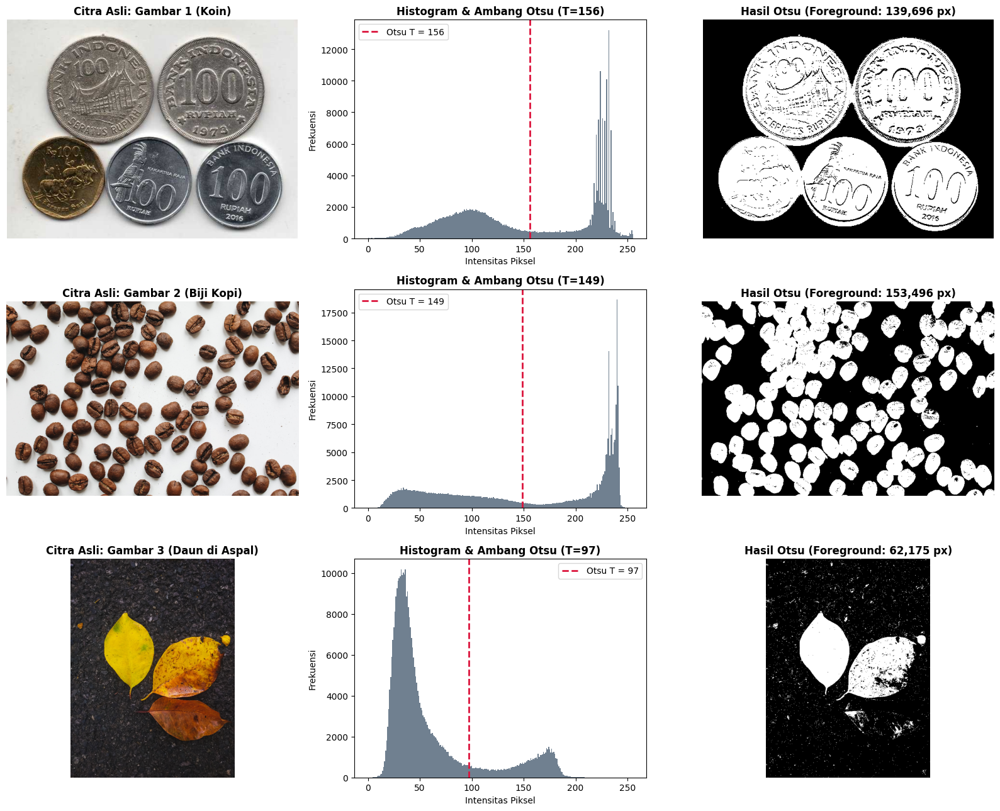

In [3]:
otsu_results = {}
otsu_thresholds = {}
otsu_std_objs = {}

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    rgb = images_rgb[fname]
    gray = images_gray[fname]

    mask_otsu, best_T, hist, std_obj = otsu_threshold_manual(gray, invert_foreground=cfg['invert'])
    otsu_results[fname] = mask_otsu
    otsu_thresholds[fname] = best_T
    otsu_std_objs[fname] = std_obj

    # Kolom 1: Citra Asli
    axes[idx, 0].imshow(rgb)
    axes[idx, 0].set_title(f"Citra Asli: {cfg['name']}", fontweight='bold')
    axes[idx, 0].axis('off')

    # Kolom 2: Histogram & Garis Threshold Otsu
    axes[idx, 1].bar(range(256), hist, color='slategray', width=1.0)
    axes[idx, 1].axvline(best_T, color='crimson', linestyle='--', linewidth=2, label=f'Otsu T = {best_T}')
    axes[idx, 1].set_title(f"Histogram & Ambang Otsu (T={best_T})", fontweight='bold')
    axes[idx, 1].set_xlabel("Intensitas Piksel")
    axes[idx, 1].set_ylabel("Frekuensi")
    axes[idx, 1].legend()

    # Kolom 3: Hasil Segmentasi Otsu (Tanpa Morfologi)
    axes[idx, 2].imshow(mask_otsu, cmap='gray', vmin=0, vmax=1)
    axes[idx, 2].set_title(f"Hasil Otsu (Foreground: {np.sum(mask_otsu):,} px)", fontweight='bold')
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

## **Region Growing**

### Definisi Fungsi

In [4]:
def generate_seeds_manual(gray_img, ref_T, invert_foreground=False, step=25):
    """Menentukan titik-titik initial seed (K) secara otomatis pada area inti objek."""
    h, w = gray_img.shape
    seeds = []
    strict_T = ref_T * 0.75 if invert_foreground else ref_T + (255 - ref_T) * 0.25

    for r in range(step // 2, h, step):
        for c in range(step // 2, w, step):
            if invert_foreground and gray_img[r, c] < strict_T:
                seeds.append((r, c))
            elif not invert_foreground and gray_img[r, c] > strict_T:
                seeds.append((r, c))

    if not seeds:
        seeds.append((h // 2, w // 2))
    return seeds

def region_growing_manual(gray_img, seeds, threshold_T=20):
    """
    Implementasi Region Growing dari nol menggunakan antrean (BFS).
    Menambahkan tetangga q ke dalam region jika |Ip - Iq| < T.
    """
    h, w = gray_img.shape
    segmented = np.zeros((h, w), dtype=np.uint8)
    visited = np.zeros((h, w), dtype=bool)
    queue = deque()

    for (sy, sx) in seeds:
        if 0 <= sy < h and 0 <= sx < w and not visited[sy, sx]:
            segmented[sy, sx] = 1
            visited[sy, sx] = True
            queue.append((sy, sx, float(gray_img[sy, sx])))

    neighbors = [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]

    while queue:
        py, px, seed_val = queue.popleft()
        Ip = float(gray_img[py, px])

        for dy, dx in neighbors:
            qy, qx = py + dy, px + dx
            if 0 <= qy < h and 0 <= qx < w and not visited[qy, qx]:
                visited[qy, qx] = True
                Iq = float(gray_img[qy, qx])
                # Kriteria homogenitas lokal |Ip - Iq| < T dan konsistensi terhadap seed
                if abs(Ip - Iq) < threshold_T and abs(seed_val - Iq) < (threshold_T * 1.8):
                    segmented[qy, qx] = 1
                    queue.append((qy, qx, seed_val))

    return segmented

### Implementasi

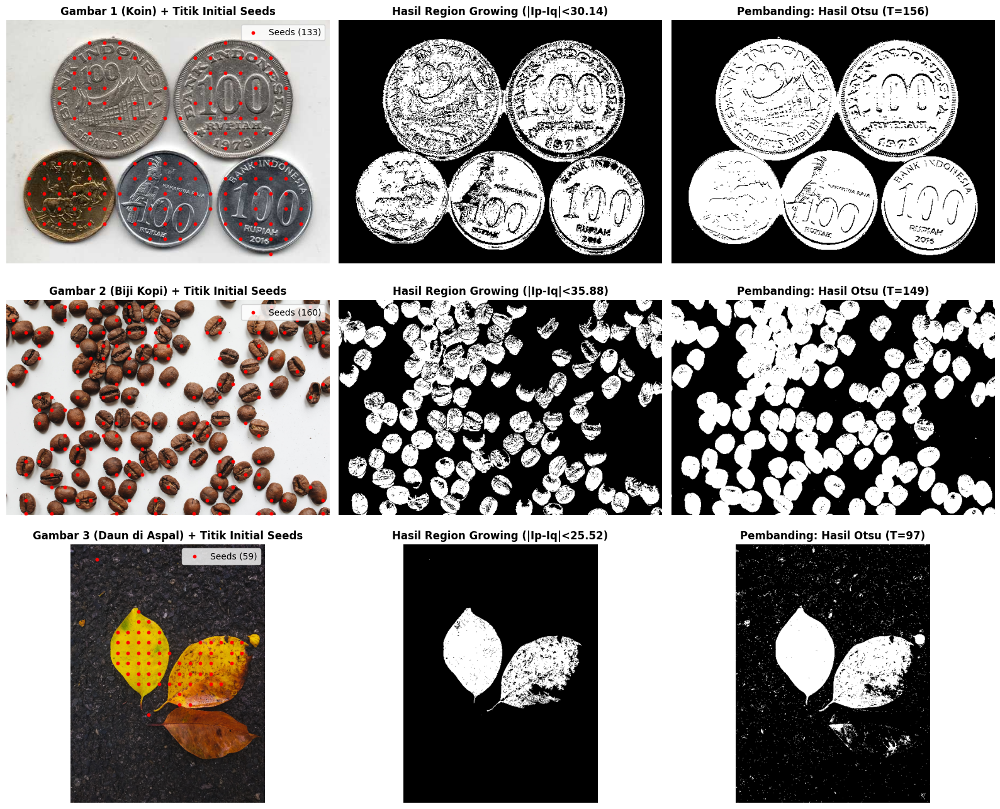

In [5]:
rg_results = {}

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    rgb = images_rgb[fname]
    gray = images_gray[fname]
    ref_T = otsu_thresholds[fname]
    std_obj = otsu_std_objs[fname]

    seeds = generate_seeds_manual(gray, ref_T, invert_foreground=cfg['invert'], step=28)
    mask_rg = region_growing_manual(gray, seeds, threshold_T=std_obj)
    rg_results[fname] = mask_rg

    # Kolom 1: Citra Asli + Titik Seed
    axes[idx, 0].imshow(rgb)
    sy_list, sx_list = [s[0] for s in seeds], [s[1] for s in seeds]
    axes[idx, 0].scatter(sx_list, sy_list, c='red', s=10, label=f'Seeds ({len(seeds)})')
    axes[idx, 0].set_title(f"{cfg['name']} + Titik Initial Seeds", fontweight='bold')
    axes[idx, 0].legend(loc='upper right')
    axes[idx, 0].axis('off')

    # Kolom 2: Hasil Region Growing (Tanpa Morfologi)
    axes[idx, 1].imshow(mask_rg, cmap='gray', vmin=0, vmax=1)
    axes[idx, 1].set_title(f"Hasil Region Growing (|Ip-Iq|<{std_obj:.2f})", fontweight='bold')
    axes[idx, 1].axis('off')

    # Kolom 3: Perbandingan Langsung dengan Hasil Otsu
    axes[idx, 2].imshow(otsu_results[fname], cmap='gray', vmin=0, vmax=1)
    axes[idx, 2].set_title(f"Pembanding: Hasil Otsu (T={ref_T})", fontweight='bold')
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

# **Operasi Morfologi**

## **Erosi**

### Definisi Fungsi

In [6]:
def create_structuring_element(size=7, shape='disk'):
    """Membuat Structuring Element (SE) biner berukuran size x size."""
    se = np.zeros((size, size), dtype=np.uint8)
    center = size // 2
    for i in range(size):
        for j in range(size):
            if shape == 'square':
                se[i, j] = 1
            elif shape == 'disk':
                if ((i - center) ** 2 + (j - center) ** 2) <= (center ** 2 + 0.5):
                    se[i, j] = 1
    return se

def erode_manual(binary_img, se):
    """
    Implementasi Binary Erosion tanpa library (menggunakan pergeseran matriks).
    Piksel foreground (1) dipertahankan hanya jika seluruh elemen SE bernilai 1
    cocok dengan piksel foreground di bawahnya.
    """
    h, w = binary_img.shape
    se_h, se_w = se.shape
    pad_y, pad_x = se_h // 2, se_w // 2

    padded = np.pad(binary_img, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=1)
    eroded = np.ones((h, w), dtype=np.uint8)

    for dy in range(se_h):
        for dx in range(se_w):
            if se[dy, dx] == 1:
                eroded = np.minimum(eroded, padded[dy : dy + h, dx : dx + w])
    return eroded

### Implementasi

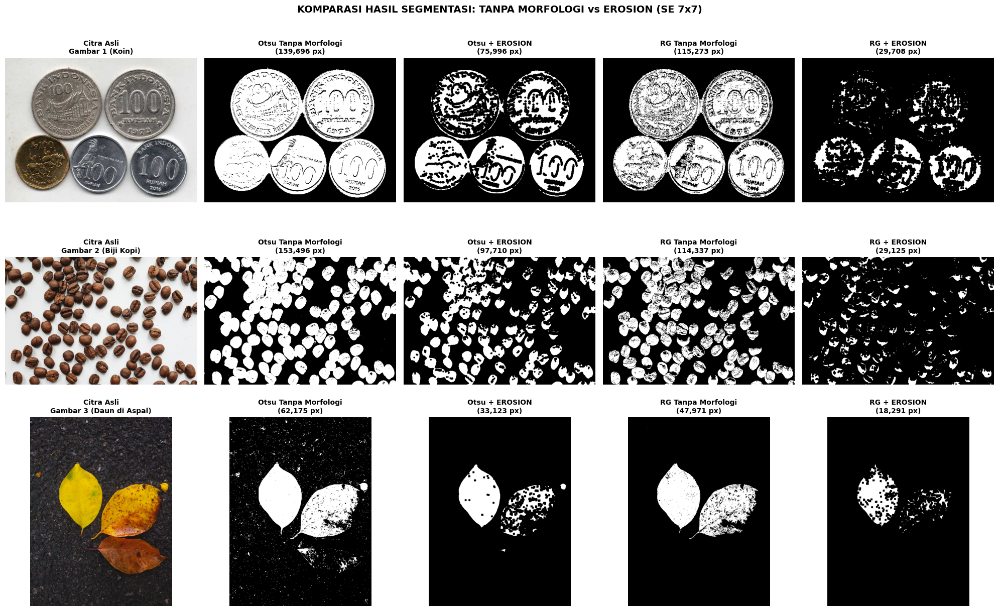

In [7]:
SE_SIZE = 7
erosion_otsu = {}
erosion_rg = {}

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    se = create_structuring_element(size=SE_SIZE, shape=cfg['se_shape'])

    raw_otsu = otsu_results[fname]
    raw_rg = rg_results[fname]

    ero_otsu = erode_manual(raw_otsu, se)
    ero_rg = erode_manual(raw_rg, se)

    erosion_otsu[fname] = ero_otsu
    erosion_rg[fname] = ero_rg

    panels = [
        (images_rgb[fname], f"Citra Asli\n{cfg['name']}", None),
        (raw_otsu, f"Otsu Tanpa Morfologi\n({np.sum(raw_otsu):,} px)", 'gray'),
        (ero_otsu, f"Otsu + EROSION\n({np.sum(ero_otsu):,} px)", 'gray'),
        (raw_rg, f"RG Tanpa Morfologi\n({np.sum(raw_rg):,} px)", 'gray'),
        (ero_rg, f"RG + EROSION\n({np.sum(ero_rg):,} px)", 'gray')
    ]

    for col, (img_data, title_txt, cmap_val) in enumerate(panels):
        axes[idx, col].imshow(img_data, cmap=cmap_val)
        axes[idx, col].set_title(title_txt, fontsize=10, fontweight='bold')
        axes[idx, col].axis('off')

plt.suptitle(f"KOMPARASI HASIL SEGMENTASI: TANPA MORFOLOGI vs EROSION (SE {SE_SIZE}x{SE_SIZE})", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## **Dilasi**

### Definisi Fungsi

In [8]:
def dilate_manual(binary_img, se):
    h, w = binary_img.shape
    se_h, se_w = se.shape
    pad_y, pad_x = se_h // 2, se_w // 2

    padded = np.pad(binary_img, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=0)
    dilated = np.zeros((h, w), dtype=np.uint8)

    for dy in range(se_h):
        for dx in range(se_w):
            if se[dy, dx] == 1:
                dilated = np.maximum(dilated, padded[dy : dy + h, dx : dx + w])
    return dilated

### Implementasi

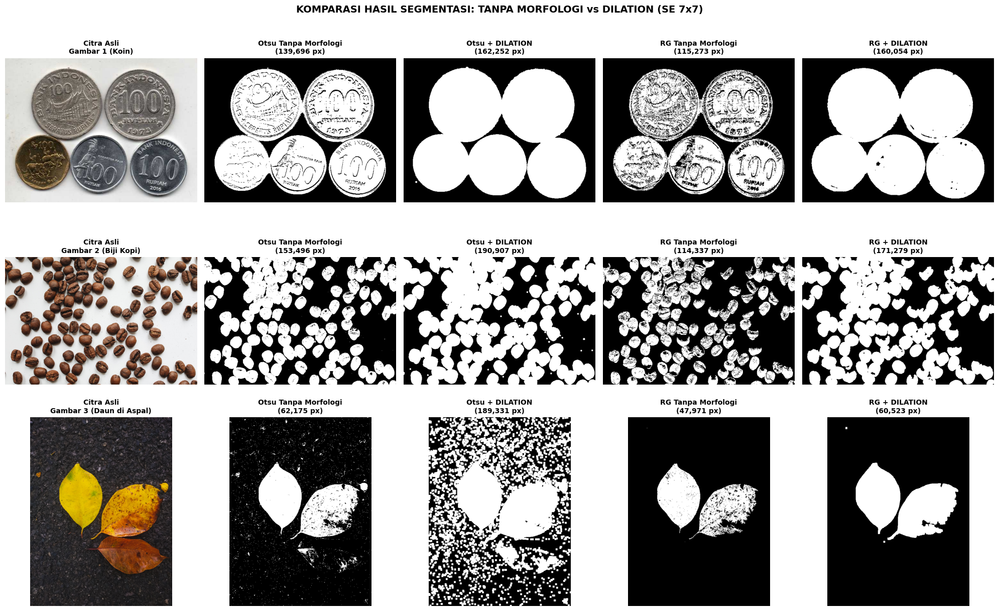

In [9]:
dilation_otsu = {}
dilation_rg = {}

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    se = create_structuring_element(size=SE_SIZE, shape=cfg['se_shape'])

    raw_otsu = otsu_results[fname]
    raw_rg = rg_results[fname]

    dil_otsu = dilate_manual(raw_otsu, se)
    dil_rg = dilate_manual(raw_rg, se)

    dilation_otsu[fname] = dil_otsu
    dilation_rg[fname] = dil_rg

    panels = [
        (images_rgb[fname], f"Citra Asli\n{cfg['name']}", None),
        (raw_otsu, f"Otsu Tanpa Morfologi\n({np.sum(raw_otsu):,} px)", 'gray'),
        (dil_otsu, f"Otsu + DILATION\n({np.sum(dil_otsu):,} px)", 'gray'),
        (raw_rg, f"RG Tanpa Morfologi\n({np.sum(raw_rg):,} px)", 'gray'),
        (dil_rg, f"RG + DILATION\n({np.sum(dil_rg):,} px)", 'gray')
    ]

    for col, (img_data, title_txt, cmap_val) in enumerate(panels):
        axes[idx, col].imshow(img_data, cmap=cmap_val)
        axes[idx, col].set_title(title_txt, fontsize=10, fontweight='bold')
        axes[idx, col].axis('off')

plt.suptitle(f"KOMPARASI HASIL SEGMENTASI: TANPA MORFOLOGI vs DILATION (SE {SE_SIZE}x{SE_SIZE})", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## **Opening**

### Definisi Fungsi

In [10]:
def opening_manual(binary_img, se):
    eroded = erode_manual(binary_img, se)
    opened = dilate_manual(eroded, se)
    return opened

### Implementasi

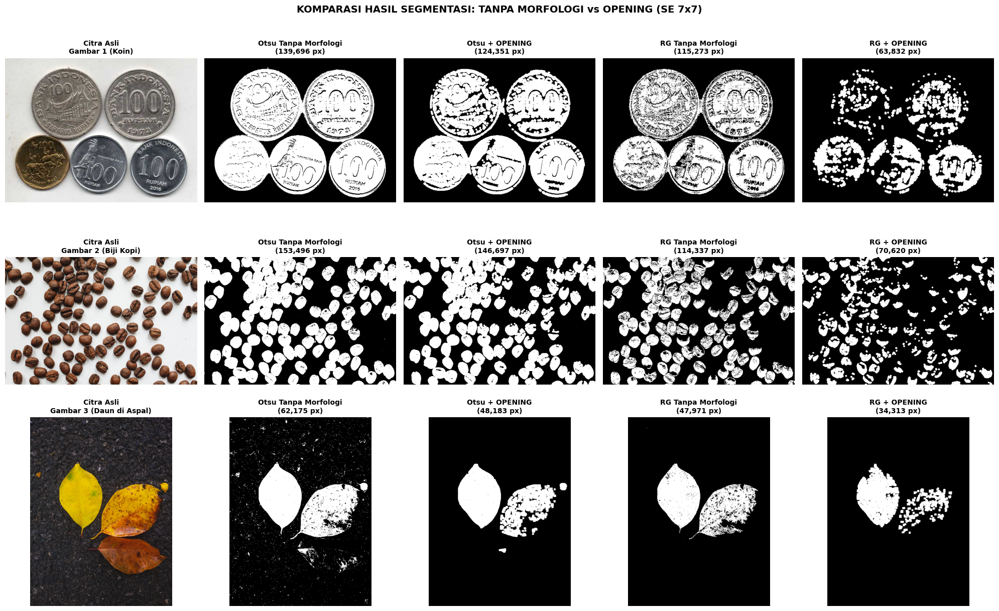

In [11]:
opening_otsu = {}
opening_rg = {}

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    se = create_structuring_element(size=SE_SIZE, shape=cfg['se_shape'])

    raw_otsu = otsu_results[fname]
    raw_rg = rg_results[fname]

    open_otsu = opening_manual(raw_otsu, se)
    open_rg = opening_manual(raw_rg, se)

    opening_otsu[fname] = open_otsu
    opening_rg[fname] = open_rg

    panels = [
        (images_rgb[fname], f"Citra Asli\n{cfg['name']}", None),
        (raw_otsu, f"Otsu Tanpa Morfologi\n({np.sum(raw_otsu):,} px)", 'gray'),
        (open_otsu, f"Otsu + OPENING\n({np.sum(open_otsu):,} px)", 'gray'),
        (raw_rg, f"RG Tanpa Morfologi\n({np.sum(raw_rg):,} px)", 'gray'),
        (open_rg, f"RG + OPENING\n({np.sum(open_rg):,} px)", 'gray')
    ]

    for col, (img_data, title_txt, cmap_val) in enumerate(panels):
        axes[idx, col].imshow(img_data, cmap=cmap_val)
        axes[idx, col].set_title(title_txt, fontsize=10, fontweight='bold')
        axes[idx, col].axis('off')

plt.suptitle(f"KOMPARASI HASIL SEGMENTASI: TANPA MORFOLOGI vs OPENING (SE {SE_SIZE}x{SE_SIZE})", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## **Closing**

### Definisi Fungsi

In [12]:
def closing_manual(binary_img, se):
    dilated = dilate_manual(binary_img, se)
    closed = erode_manual(dilated, se)
    return closed

### Implementasi

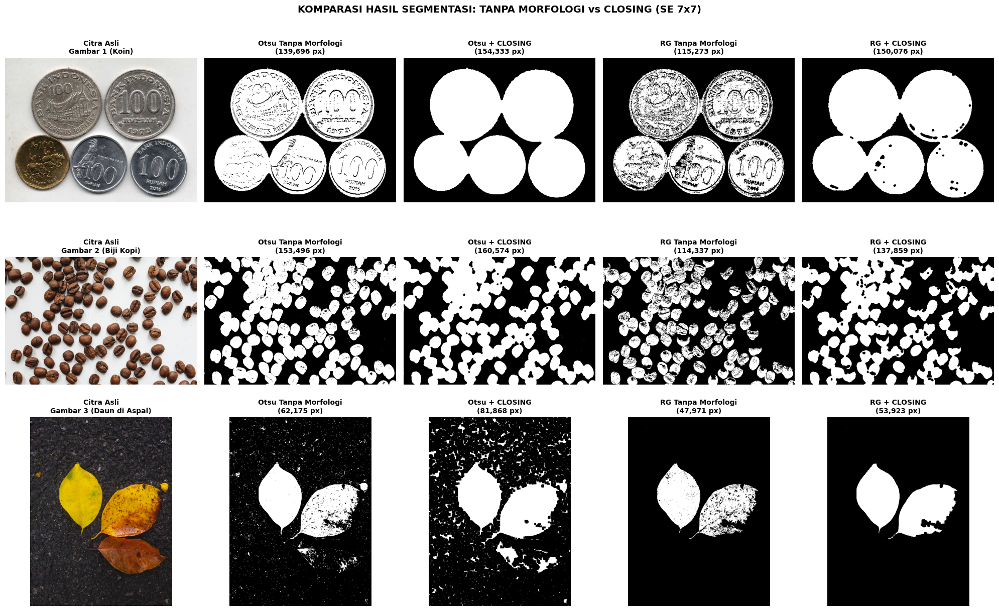

In [13]:
closing_otsu = {}
closing_rg = {}

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    se = create_structuring_element(size=SE_SIZE, shape=cfg['se_shape'])

    raw_otsu = otsu_results[fname]
    raw_rg = rg_results[fname]

    close_otsu = closing_manual(raw_otsu, se)
    close_rg = closing_manual(raw_rg, se)

    closing_otsu[fname] = close_otsu
    closing_rg[fname] = close_rg

    panels = [
        (images_rgb[fname], f"Citra Asli\n{cfg['name']}", None),
        (raw_otsu, f"Otsu Tanpa Morfologi\n({np.sum(raw_otsu):,} px)", 'gray'),
        (close_otsu, f"Otsu + CLOSING\n({np.sum(close_otsu):,} px)", 'gray'),
        (raw_rg, f"RG Tanpa Morfologi\n({np.sum(raw_rg):,} px)", 'gray'),
        (close_rg, f"RG + CLOSING\n({np.sum(close_rg):,} px)", 'gray')
    ]

    for col, (img_data, title_txt, cmap_val) in enumerate(panels):
        axes[idx, col].imshow(img_data, cmap=cmap_val)
        axes[idx, col].set_title(title_txt, fontsize=10, fontweight='bold')
        axes[idx, col].axis('off')

plt.suptitle(f"KOMPARASI HASIL SEGMENTASI: TANPA MORFOLOGI vs CLOSING (SE {SE_SIZE}x{SE_SIZE})", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# **Rangkuman**

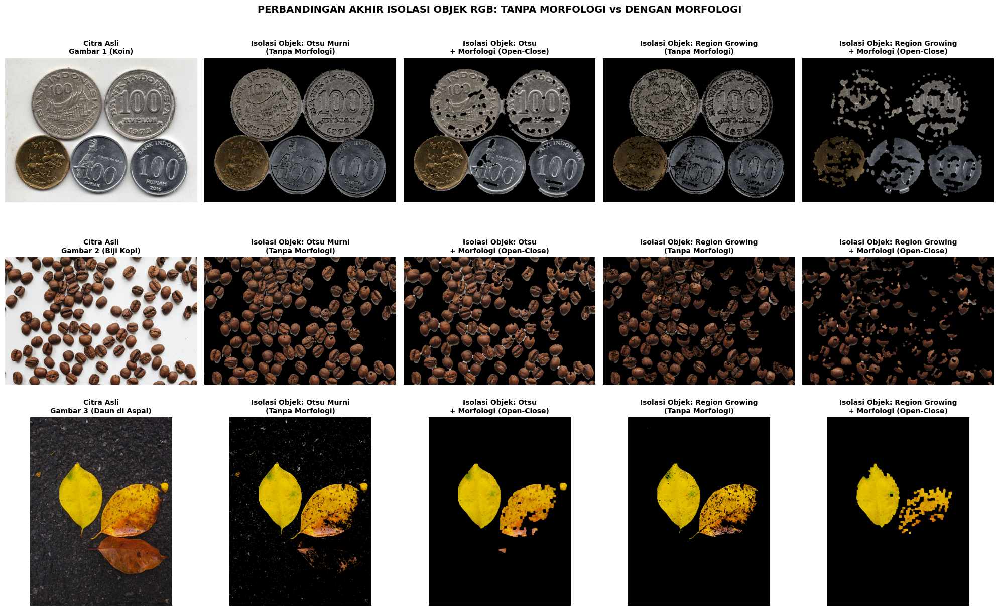

In [14]:
def apply_mask_to_rgb(rgb_img, binary_mask):
    """Mengisolasi objek pada citra RGB asli menggunakan binary mask hasil segmentasi."""
    masked_rgb = np.zeros_like(rgb_img)
    for c in range(3):
        masked_rgb[:, :, c] = rgb_img[:, :, c] * binary_mask
    return masked_rgb

fig, axes = plt.subplots(3, 5, figsize=(20, 12))

for idx, cfg in enumerate(dataset_config):
    fname = cfg['file']
    rgb = images_rgb[fname]
    se = create_structuring_element(size=SE_SIZE, shape=cfg['se_shape'])

    # Kombinasi Opening -> Closing untuk mendapatkan mask paling bersih (bebas noise latar & bebas lubang)
    best_morph_otsu = closing_manual(opening_otsu[fname], se)
    best_morph_rg = closing_manual(opening_rg[fname], se)

    panels = [
        (rgb, f"Citra Asli\n{cfg['name']}"),
        (apply_mask_to_rgb(rgb, otsu_results[fname]), "Isolasi Objek: Otsu Murni\n(Tanpa Morfologi)"),
        (apply_mask_to_rgb(rgb, best_morph_otsu), "Isolasi Objek: Otsu\n+ Morfologi (Open-Close)"),
        (apply_mask_to_rgb(rgb, rg_results[fname]), "Isolasi Objek: Region Growing\n(Tanpa Morfologi)"),
        (apply_mask_to_rgb(rgb, best_morph_rg), "Isolasi Objek: Region Growing\n+ Morfologi (Open-Close)")
    ]

    for col, (img_vis, title_txt) in enumerate(panels):
        axes[idx, col].imshow(img_vis)
        axes[idx, col].set_title(title_txt, fontsize=10, fontweight='bold')
        axes[idx, col].axis('off')

plt.suptitle("PERBANDINGAN AKHIR ISOLASI OBJEK RGB: TANPA MORFOLOGI vs DENGAN MORFOLOGI", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()